# 04. Нейросеть: каузальная TCN против LDA

**Вопрос этапа:** даёт ли нейросеть на сыром сигнале что-то сверх LDA на признаках Хаджинса,
и если да, то где — внутри сессии или при переносе на другой день и другого человека?

Цепочка обработки:
**сырой сигнал → тот же каузальный фильтр 20–450 Гц → прореживание до 1024 Гц → TCN → жест каждые 50 мс.**

Эксперименты (`python run.py --config configs/<имя>.yaml`): подбор на dev — `tcn_dev_e1/e2/e3`,
итог на test — `tcn_test_e1/e2/e3`; для сравнения LDA и LightGBM — `baseline_dev_e*`, `baseline_test_e*`.
Код: `src/signals.py`, `src/tcn.py`, `run_tcn` в `run.py`. Ноутбук ничего не обучает: он читает готовые результаты.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.stats import binomtest
from IPython.display import Image, display

import tcn
import evaluate
import viz
from data import GESTURE_SHORT
viz.setup()
pd.set_option("display.width", 160)


def load(name: str) -> dict:
    """Result file results/<name>.json."""
    return json.loads((ROOT / "results" / f"{name}.json").read_text(encoding="utf-8"))


def per_person(name: str, model: str | None = None) -> pd.Series:
    """Balanced accuracy (%) per participant from a result file, optionally for one model."""
    pp = pd.DataFrame(load(name)["per_participant"])
    if model is not None:
        pp = pp[pp.model == model]
    return pp.set_index("participant").bal_acc * 100

## 1. Каузальная свёртка и дилатация

**Термины:**
- **Свёртка по времени** — обучаемый фильтр: каждый выход — взвешенная сумма нескольких отсчётов входа,
  $y[t] = \sum_j w_j\,x[t-j]$. По сути это FIR-фильтр из этапа 3, только коэффициенты $w_j$ подбирает обучение,
  а не формула Баттерворта. Сеть сама решает, какие частоты и формы сигнала полезны.
- **Каузальная** свёртка берёт только $x[t], x[t-1], \dots$: нули дописываются только слева.
  Как и наш фильтр, она может работать на потоке — браслет будущего не знает.
- **Дилатация** $d$ — свёртка смотрит не на соседние отсчёты, а через $d$: $x[t],\ x[t-d],\ x[t-2d]$.
  Если увеличивать $d$ от слоя к слою, за несколько слоёв сеть охватывает длинный отрезок прошлого.
- **TCN** (temporal convolutional network) — стопка таких каузальных свёрток с растущей дилатацией.

## 2. Рецептивное поле

**Рецептивное поле** — сколько отсчётов прошлого влияет на один выход сети. Это аналог длины окна у LDA:
оно определяет, сколько информации видит модель и насколько она запаздывает. У нас 6 блоков по 2 свёртки с ядром $k = 3$:

$$\text{RF} = 1 + 2\,(k-1)\sum d = 1 + 4\,(1+2+4+8+16+20) = 205 \text{ отсчётов} = 200 \text{ мс при } 1024 \text{ Гц}.$$

Дилатации подобраны так, чтобы рецептивное поле **ровно совпало с окном 200 мс** у LDA и LightGBM, а решения
принимались в те же 93 момента на попытку. Тогда сравнение честное: обе модели видят одинаковый отрезок прошлого и
имеют одинаковую задержку. Если сеть выиграет, то за счёт того, **как** она использует сигнал, а не за счёт того, что видит больше.

Ниже — проверка на необученной сети: (1) импульс в момент 300 влияет только на выходы 300…504;
(2) если полностью изменить сигнал после момента 450, ни один выход до 450 не меняется.

,дилатация d,"рецептивное поле, отсчётов",мс
после блока,,,
1,1,5,5
2,2,13,13
3,4,29,28
4,8,61,60
5,16,125,122
6,20,205,200


импульс в t = 300 меняет выходы с 300 по 504 (205 отсчётов)
изменение будущего после t = 449: наибольшее изменение выходов до t = 450 — 0.0e+00


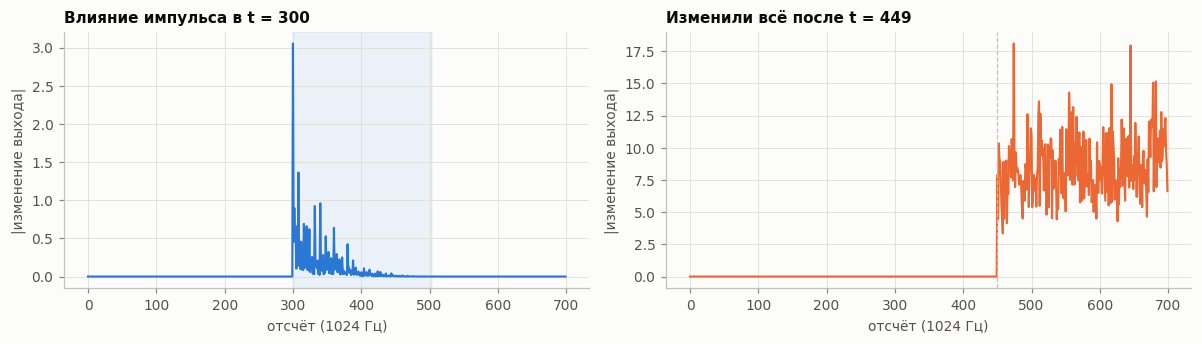

In [2]:
torch.manual_seed(0)
net = tcn.TCN(12, 17).eval()
dil = [1, 2, 4, 8, 16, 20]
rf = 1 + np.cumsum([4 * d for d in dil])
display(pd.DataFrame({"после блока": range(1, 7), "дилатация d": dil, "рецептивное поле, отсчётов": rf,
                      "мс": (1000 * rf / 1024).round(0).astype(int)}).set_index("после блока"))

# A linear copy (ReLU -> identity) shows the full span of influence; in the real network some paths can be
# switched off by ReLU, and the influence may end a few samples earlier.
lin = tcn.TCN(12, 17).eval()
lin.load_state_dict(net.state_dict())
for block in lin.blocks:
    for i, layer in enumerate(block.net):
        if isinstance(layer, torch.nn.ReLU):
            block.net[i] = torch.nn.Identity()

x = torch.randn(1, 12, 700)
with torch.no_grad():
    xi = x.clone(); xi[:, :, 300] += 5.0                         # impulse at t = 300
    d_imp = (lin(xi) - lin(x)).abs().amax(1)[0].numpy()
    xf = x.clone(); xf[:, :, 450:] = 10 * torch.randn(1, 12, 250)  # replace the whole future after t = 449
    d_fut = (net(xf) - net(x)).abs().amax(1)[0].numpy()

hit = np.flatnonzero(d_imp > 1e-9)
print(f"импульс в t = 300 меняет выходы с {hit.min()} по {hit.max()} ({hit.max() - hit.min() + 1} отсчётов)")
print(f"изменение будущего после t = 449: наибольшее изменение выходов до t = 450 — {d_fut[:450].max():.1e}")

t = np.arange(700)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].plot(t, d_imp, color=viz.SERIES[0])
axes[0].axvspan(300, 300 + 204, color=viz.SERIES[0], alpha=0.08)
axes[0].set_title("Влияние импульса в t = 300")
axes[1].plot(t, d_fut, color=viz.SERIES[1])
axes[1].axvline(450, color=viz.AXIS, ls="--", lw=0.8)
axes[1].set_title("Изменили всё после t = 449")
for ax in axes:
    ax.set_xlabel("отсчёт (1024 Гц)"); ax.set_ylabel("|изменение выхода|")
fig.tight_layout()
viz.save(fig, "04_receptive_field")
plt.show()

**Как читать:** слева влияние импульса занимает ровно 205 отсчётов после него (закрашено) — это и есть рецептивное поле.
Справа выходы до момента 450 не изменились вовсе: сеть каузальная, будущего не видит.

## 3. Архитектура и обучаемые части

```
вход: 12 каналов × время (1024 Гц)
  ÷ scale             SD каждого канала по обучающей части (не обучается)
  stem: свёртка 1×1   12 → 64 канала
  6 блоков, d = 1, 2, 4, 8, 16, 20:
      x → [свёртка → BatchNorm → ReLU → свёртка → BatchNorm → ReLU] → + x
  head: свёртка 1×1   64 → 17
выход: 17 оценок жестов в каждый момент; берём наибольшую каждые 50 мс
```

- **stem** — в каждый момент берёт 12 значений каналов и выдаёт 64 их линейные комбинации. По смыслу —
  обучаемые пространственные фильтры («W4 минус W10», «сумма W3–W5»).
- **Свёртки в блоках** — обучаемые FIR-фильтры, которые одновременно смешивают каналы.
- **BatchNorm** — для каждого из 64 каналов вычитает среднее и делит на SD, затем умножает на обучаемое $\gamma$ и
  прибавляет обучаемое $\beta$. При инференсе использует средние, накопленные при обучении. Пересчёт этих средних
  по новой сессии — метод адаптации AdaBN, этап 5.
- **ReLU** — $\max(0, y)$, единственная нелинейность. Связка «фильтр → ReLU (выпрямление) → усреднение следующими
  свёртками» — это то, как считается MAV, так что сеть может сама собрать «амплитуду в такой-то полосе на такой-то
  комбинации каналов».
- **Остаточная связь** $x + f(x)$ — блок добавляет к сигналу поправку, а не переписывает его; облегчает обучение.
- **head** — линейный классификатор на 64 выученных признаках, такой же по форме, как у LDA на 60 признаках Хаджинса.

Получается то же разделение, что у LDA: **извлечение признаков → линейный классификатор**. Разница в том, что
признаки сети выучены, а не заданы формулами.

In [3]:
conv = sum(p.numel() for b in net.blocks for l in b.net if isinstance(l, tcn.CausalConv1d) for p in l.parameters())
bn = sum(p.numel() for b in net.blocks for l in b.net if isinstance(l, torch.nn.BatchNorm1d) for p in l.parameters())
parts = pd.DataFrame([
    {"часть": "stem: свёртка 1×1, 12 → 64", "параметров": tcn.n_params(net.stem)},
    {"часть": "12 каузальных свёрток в блоках, 64 → 64, ядро 3", "параметров": conv},
    {"часть": "12 BatchNorm (γ, β)", "параметров": bn},
    {"часть": "head: свёртка 1×1, 64 → 17", "параметров": tcn.n_params(net.head)},
    {"часть": "всего", "параметров": tcn.n_params(net)},
]).set_index("часть")
display(parts)
macs = 12 * 64 + 12 * 64 * 64 * 3 + 64 * 17          # multiply-adds per time step
print(f"память в float32: {4 * tcn.n_params(net) / 1024:.0f} КБ")
print(f"умножений на один отсчёт: {macs:,}; в секунду при 1024 Гц: {macs * 1024 / 1e6:.0f} млн")
print("для сравнения LDA: 60 × 17 весов + 17 сдвигов ≈ 1 тыс. умножений на решение (раз в 50 мс)")

,параметров
часть,
"stem: свёртка 1×1, 12 → 64",832
"12 каузальных свёрток в блоках, 64 → 64, ядро 3",148224
"12 BatchNorm (γ, β)",1536
"head: свёртка 1×1, 64 → 17",1105
всего,151697


память в float32: 593 КБ
умножений на один отсчёт: 149,312; в секунду при 1024 Гц: 153 млн
для сравнения LDA: 60 × 17 весов + 17 сдвигов ≈ 1 тыс. умножений на решение (раз в 50 мс)


**Вывод:** 98 % параметров — в 12 свёртках блоков. Сеть в сотни раз больше LDA по памяти и в тысячи раз — по вычислениям.
Поэтому она имеет смысл, только если заметно выигрывает в точности.

## 4. Как сеть обучается

- **Нормализация входа** — каждый канал делится на своё SD, посчитанное **только по обучающей части**. Эти 12 чисел
  хранятся внутри модели, так что на устройство нормализация переезжает вместе с весами.
- **Случайные куски** — из обучающих попыток берутся случайные отрезки по 1,2 с. За эпоху — 4 куска с каждой попытки.
- **Потеря** (кросс-энтропия) считается только в тех моментах куска, где рецептивное поле целиком внутри куска.
  Это ровно те моменты, где в потоке принималось бы решение.
- **Оптимизатор** AdamW, шаг 0,001, затухание весов 0,01, шаг не меняется по ходу обучения.
- **Оценка** — тот же balanced accuracy в те же 93 момента на попытку, что и у LDA, по каждому участнику × сессии.

## 5. Схема: подбор на dev, итог на test

| группа | участники | зачем |
|---|---|---|
| **dev** | 11, 21, 24, 27, 38, 6, 22, 31, 35, 40 | подбор: E1 и E2 — по каждому человеку, E3 — 5 фолдов по 2 человека (обучение на 8) |
| **test** | 5, 8, 17, 19, 25 | один прогон с замороженными настройками |

**Что подбиралось:**
- **число эпох** — автоматически: каждые 3 эпохи сеть проверяется, кривая усредняется по участникам (медиана),
  выбирается максимум **сглаженной** кривой (среднее трёх соседних точек). Максимум одной точки завышен: на плато
  кривая скачет на ±3–5 п.п., и выбирать по одной точке — значит выбирать удачный шум;
- **dropout** (случайное выключение целых каналов при обучении) — вручную: 0 против 0,2 в E1.

На test каждая сеть обучается заново ровно выбранное число эпох и проверяется один раз. С dev переносится рецепт,
а не веса: в E1 и E2 модели персональные, и веса чужого человека бесполезны.

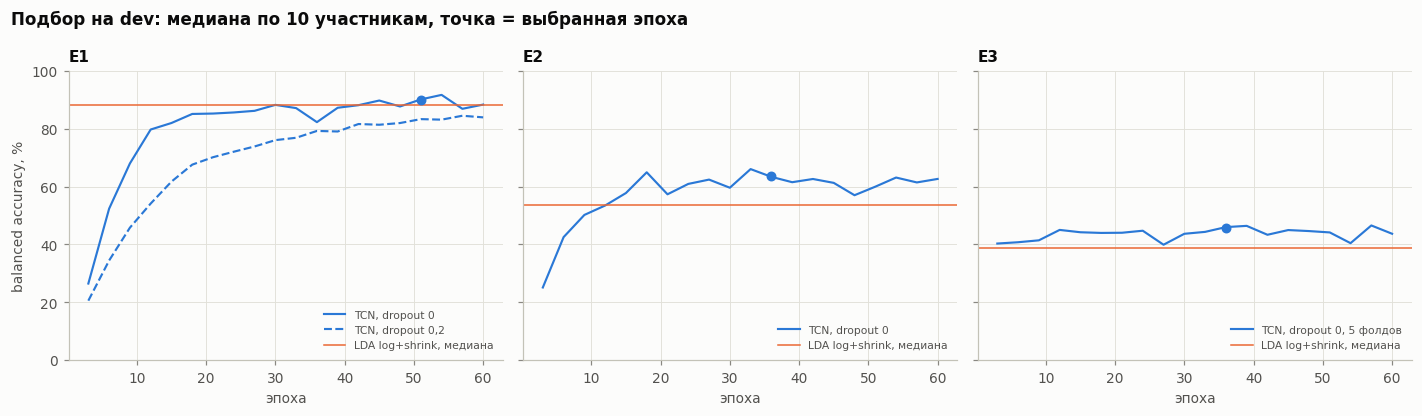

E1: эпоха 51, сглаженная медиана 89.8 %
E2: эпоха 36, сглаженная медиана 63.6 %
E3: эпоха 36, сглаженная медиана 45.6 %


In [4]:
def smoothed_best(curve: np.ndarray) -> tuple[int, float]:
    """Epoch with the highest 3-point moving average of the median curve, and that average (%)."""
    s = np.convolve(curve[:, 1], np.ones(3) / 3, "valid")
    i = int(s.argmax())
    return int(curve[i + 1, 0]), 100 * s[i]


runs = {"E1": [("tcn_dev_e1", "dropout 0"), ("tcn_dev_e1_drop0.2", "dropout 0,2")],
        "E2": [("tcn_dev_e2", "dropout 0")],
        "E3": [("tcn_dev_e3", "dropout 0, 5 фолдов")]}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
chosen = {}
for ax, (e, rs) in zip(axes, runs.items()):
    for i, (name, label) in enumerate(rs):
        c = np.array(load(name)["curve_median"][e])
        ax.plot(c[:, 0], 100 * c[:, 1], color=viz.SERIES[0], ls="-" if i == 0 else "--", label=f"TCN, {label}")
        if i == 0:
            chosen[e] = smoothed_best(c)
            ax.scatter(*chosen[e], color=viz.SERIES[0], s=30, zorder=3)
    lda = per_person(f"baseline_dev_{e.lower()}", "lda_log_shrink").median()
    ax.axhline(lda, color=viz.SERIES[1], lw=1, label="LDA log+shrink, медиана")
    ax.set_title(e)
    ax.set_xlabel("эпоха")
    ax.legend(fontsize=7, loc="lower right")
axes[0].set_ylabel("balanced accuracy, %")
axes[0].set_ylim(0, 100)
fig.suptitle("Подбор на dev: медиана по 10 участникам, точка = выбранная эпоха", x=0.01, ha="left",
             fontsize=11, fontweight="bold", color=viz.INK)
fig.tight_layout()
viz.save(fig, "04_dev_curves")
plt.show()
for e, (ep, v) in chosen.items():
    print(f"{e}: эпоха {ep}, сглаженная медиана {v:.1f} %")

**Как читать:**
- **E1:** без dropout сеть за ~18 эпох выходит на плато 85–90 %. С dropout 0,2 она учится медленнее и к 60-й эпохе
  всё ещё ниже (84 %). Внутри сессии запоминать особенности надевания не вредно — тест на том же надевании, —
  поэтому регуляризация здесь не нужна. Выбор: **dropout 0, 51 эпоха**.
- **E2:** к ~18-й эпохе ~65 %, дальше плато 57–66 % — **выше линии LDA** (53,5 %). Выбор: **36 эпох**.
- **E3:** кривая почти плоская: 40 % уже на 3-й эпохе, с 12-й плато 44–46 %. Обучающих данных много (8 человек),
  и за одну эпоху сеть делает ~180 шагов. Выбор: **36 эпох** (12–15 дали бы то же). Линия LDA здесь — схема
  «один человек в тест» (обучение на 9), то есть у LDA в обучении на одного человека больше.

## 6. Результаты на тесте

experiment     E1                            E2                            E3                        
model         TCN LDA log+shrink LightGBM   TCN LDA log+shrink LightGBM   TCN LDA log+shrink LightGBM
participant                                                                                          
5            92.8           87.8     79.8  42.4           38.0     36.6  60.7           51.1     45.4
8            83.0           80.7     77.6  76.5           64.2     60.2  57.4           44.1     44.6
17           91.7           94.6     86.1  35.3           52.2     27.5  50.6           49.5     44.9
19           86.6           82.2     78.8  60.3           52.5     43.3  49.4           35.6     38.0
25           91.8           91.4     76.1  46.9           32.2     31.3  57.1           40.7     33.5

mean             median               min               max            
experiment        E1    E2    E3     E1    E2    E3    E1    E2    E3    E1    E2    E3
model                                                                                  
TCN             89.2  52.3  55.0   91.7  46.9  57.1  83.0  35.3  49.4  92.8  76.5  60.7
LDA log+shrink  87.3  47.8  44.2   87.8  52.2  44.1  80.7  32.2  35.6  94.6  64.2  51.1
LightGBM        79.7  39.8  41.3   78.8  36.6  44.6  76.1  27.5  33.5  86.1  60.2  45.4

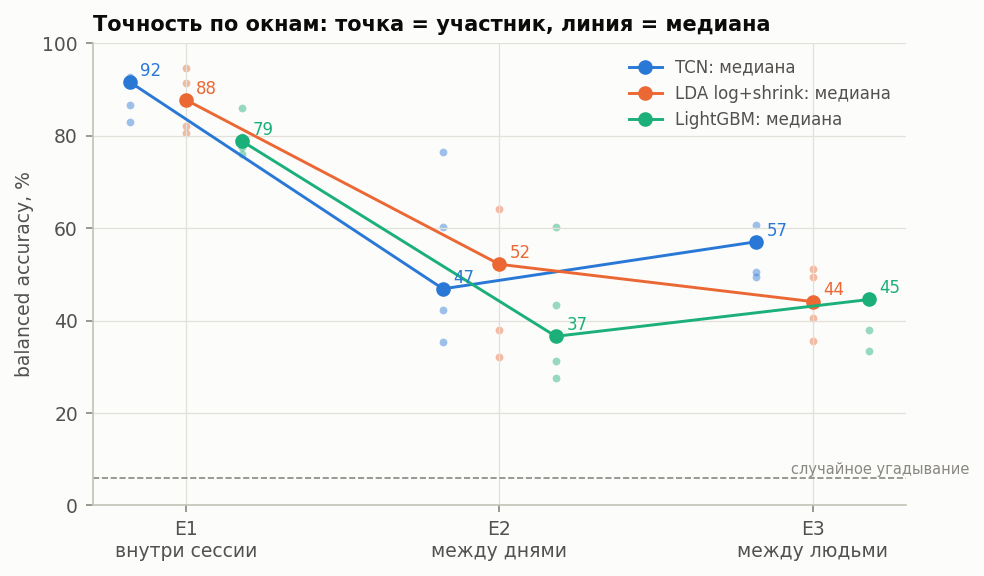

In [5]:
names = {"tcn": "TCN", "lda_log_shrink": "LDA log+shrink", "lgbm": "LightGBM"}
rows = []
for e in ["e1", "e2", "e3"]:
    for f in [f"tcn_test_{e}", f"baseline_test_{e}"]:
        rows += load(f)["per_participant"]
test = pd.DataFrame(rows)
test["bal_acc"] *= 100
test["model"] = pd.Categorical(test.model.map(names), categories=list(names.values()), ordered=True)
test = test.sort_values("model")

display(test.pivot_table(index="participant", columns=["experiment", "model"], values="bal_acc",
                         observed=True).round(1))
display(test.groupby(["model", "experiment"], observed=True).bal_acc.agg(["mean", "median", "min", "max"])
        .round(1).unstack("experiment"))
display(Image(evaluate.plot_e1_e4(test.assign(model=test.model.astype(str), bal_acc=test.bal_acc / 100),  # the plot takes fractions
                                    "test_all", stage="04")))

**Как читать:** точки — участники, линии проходят через медианы.
- **E1:** все три модели высоко; TCN и LDA близки, LightGBM ниже.
- **E2:** по медиане TCN (46,9) ниже LDA (52,2), но по среднему выше (52,3 против 47,8), и в таблице TCN лучше
  у 4 из 5 человек. **Медиана пяти чисел — это просто третье по величине число**, и у двух моделей «третьим» оказываются
  разные люди. Модели нужно сравнивать **попарно**, по каждому человеку. Единственный, но сильный провал сети —
  участник 17 (35 против 52).
- **E3:** TCN лучше обеих моделей у всех пятерых.
- **LightGBM** хуже всех во всех экспериментах; в E2 он к тому же неустойчив (54 % на dev, 37 % на тесте).

## 7. Попарное сравнение TCN и LDA

Для каждого человека считаем разницу «TCN минус LDA log + shrink». На dev — 10 человек, на test — 5.

**Критерий знаков** — простая проверка: если бы модели были равны, TCN выигрывала бы у каждого человека с вероятностью 1/2,
и число побед подчинялось бы биномиальному распределению. p-значение — вероятность получить случайно
такой же или больший перекос.

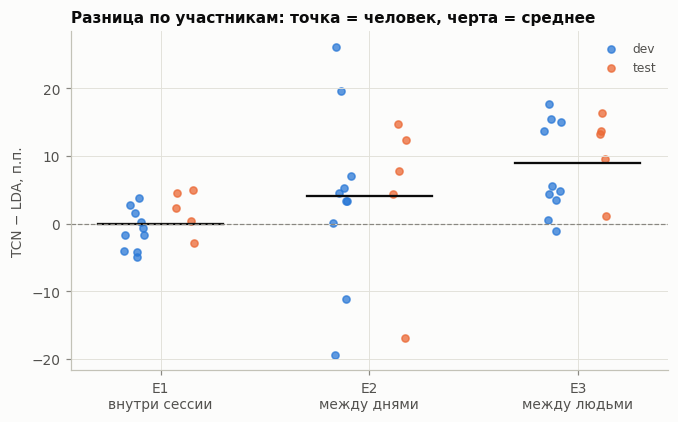

,TCN лучше,"средняя разница, п.п.",среднее на test,"критерий знаков, p"
experiment,,,,
E1,8 из 15,0.0,1.9,1.000
E2,12 из 15,4.1,4.5,0.035
E3,14 из 15,8.9,10.8,0.001


In [6]:
rows = []
for e in ["E1", "E2", "E3"]:
    for group, tcn_name, base_name in [("dev", f"tcn_dev_{e.lower()}", f"baseline_dev_{e.lower()}"),
                                       ("test", f"tcn_test_{e.lower()}", f"baseline_test_{e.lower()}")]:
        d = per_person(tcn_name) - per_person(base_name, "lda_log_shrink")
        rows += [{"experiment": e, "group": group, "participant": p, "diff": v} for p, v in d.items()]
diffs = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 4))
rng = np.random.default_rng(0)
for i, e in enumerate(["E1", "E2", "E3"]):
    for j, (group, color) in enumerate([("dev", viz.SERIES[0]), ("test", viz.SERIES[1])]):
        v = diffs[(diffs.experiment == e) & (diffs.group == group)]["diff"].to_numpy()
        ax.scatter(i + (j - 0.5) * 0.25 + rng.uniform(-0.05, 0.05, len(v)), v, color=color, s=22, alpha=0.75,
                   label=group if i == 0 else None)
    m = diffs[diffs.experiment == e]["diff"].mean()
    ax.plot([i - 0.3, i + 0.3], [m, m], color=viz.INK, lw=1.5)
ax.axhline(0, color=viz.REFERENCE, lw=0.8, ls="--")
ax.set_xticks(range(3), ["E1\nвнутри сессии", "E2\nмежду днями", "E3\nмежду людьми"])
ax.set_ylabel("TCN − LDA, п.п.")
ax.legend(fontsize=8)
ax.set_title("Разница по участникам: точка = человек, черта = среднее")
viz.save(fig, "04_tcn_minus_lda")
plt.show()

summary = []
for e, g in diffs.groupby("experiment"):
    wins, n = int((g["diff"] > 0).sum()), len(g)
    summary.append({"experiment": e, "TCN лучше": f"{wins} из {n}", "средняя разница, п.п.": round(g["diff"].mean(), 1),
                    "среднее на test": round(g[g.group == "test"]["diff"].mean(), 1),
                    "критерий знаков, p": round(binomtest(wins, n).pvalue, 3)})
display(pd.DataFrame(summary).set_index("experiment"))

**Главный вывод этапа: выигрыш сети растёт вместе со сдвигом.** Внутри сессии — ничья (сеть лучше у 8 из 15,
средняя разница 0), между днями — у 12 из 15 человек, между людьми — у 14 из 15.

План этапа спрашивал: «если нейросеть лучше в E1, но не в E3, о чём это говорит?» Получилось наоборот:
сеть **не** выигрывает там, где можно запомнить надевание, и выигрывает там, где нужно обобщать.
Гипотеза (не проверена): свёртки учат признаки формы сигнала и соотношений между каналами, которые меньше зависят
от общего уровня сигнала, чем амплитуды Хаджинса. А общий сдвиг уровня — главное, что меняется между днями и людьми (этап 3).

## 8. Своя первая сессия или десять чужих людей?

В E2 модель персональная: обучена на первой сессии того же человека. В E3 модель ни разу не видела этого человека,
но обучена на 10 других людях по 3 сессии.

In [7]:
pop = pd.DataFrame({"E2: своя сессия 1": per_person("tcn_test_e2"),
                    "E3: 10 других людей": per_person("tcn_test_e3")})
pop["E3 − E2"] = pop.iloc[:, 1] - pop.iloc[:, 0]
pop.loc["среднее"] = pop.mean()
display(pop.round(1))

,E2: своя сессия 1,E3: 10 других людей,E3 − E2
participant,,,
5,42.4,60.7,18.3
8,76.5,57.4,-19.1
17,35.3,50.6,15.2
19,60.3,49.4,-11.0
25,46.9,57.1,10.2
среднее,52.3,55.0,2.7


**Как читать:** у троих из пяти модель на чужих людях лучше персональной — на 10–18 п.п.; в среднем E3 тоже выше.
Модель E3 видела 30 разных надеваний и научилась не опираться на особенности одного. Персональная видела одно
надевание и запомнила именно его.

**Следствие для этапа 5:** выгоднее стартовать с **общей модели и подстраивать её** короткой калибровкой,
чем обучать персональную модель с нуля.

## 9. Какие жесты путаются у нового человека

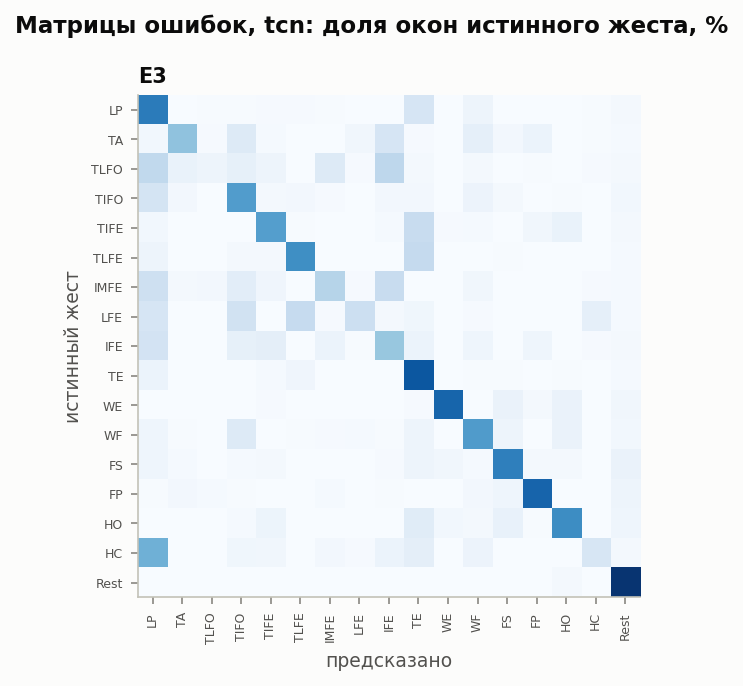

доля верно распознанных окон, %:
LP      71
TA      41
TLFO     5
TIFO    58
TIFE    57
TLFE    63
IMFE    30
LFE     22
IFE     39
TE      85
WE      79
WF      58
FS      69
FP      80
HO      64
HC      16
Rest    98

частые ошибки (истинный → предсказанный):
  HC → LP: 49 %
  TLFO → IFE: 28 %
  TLFO → LP: 26 %
  TLFE → TE: 25 %
  LFE → TLFE: 25 %


In [8]:
display(Image(ROOT / "reports" / "figures" / "04_confusion_tcn_tcn_test_e3.png"))
c = np.array(load("tcn_test_e3")["confusion"]["E3/tcn"])
cn = c / c.sum(1, keepdims=True)
print("доля верно распознанных окон, %:")
print(pd.Series(100 * np.diag(cn), index=GESTURE_SHORT).round(0).astype(int).to_string())
off = cn.copy()
np.fill_diagonal(off, 0)
top = sorted(((off[i, j], GESTURE_SHORT[i], GESTURE_SHORT[j]) for i in range(17) for j in range(17)), reverse=True)[:5]
print("\nчастые ошибки (истинный → предсказанный):")
for v, a, b in top:
    print(f"  {a} → {b}: {100 * v:.0f} %")

**Как читать:**
- Лучше всего переносятся покой и жесты всей кистью и предплечьем: TE, FP, WE.
- Хуже всего — TLFO (5 %) и HC (16 %): HC в половине случаев уходит в LP (боковой захват). Это та же пара, что путалась
  у LDA ещё на этапе 3: оба жеста — «сжимающие», работают одни и те же сгибатели пальцев.
- Общая закономерность прежняя: путаются жесты с общей главной мышцей, которые отличаются маленькой мышцей
  или одним пальцем.

## 10. Выводы

| | E1 | E2 | E3 |
|---|---|---|---|
| TCN, среднее на test | 89,2 | 52,3 | 55,0 |
| LDA log + shrink | 87,3 | 47,8 | 44,2 |
| LightGBM | 79,7 | 39,8 | 41,3 |
| TCN лучше LDA (dev + test) | 8 из 15 | 12 из 15 | 14 из 15 |

1. **Внутри сессии сложная модель не нужна**: TCN и LDA почти равны.
2. **При переносе сеть заметно лучше**, и выигрыш растёт со сдвигом: +4,5 п.п. между днями, +10,8 между людьми.
3. **Модель на многих людях лучше персональной модели одного дня** — подсказка для этапа 5.
4. **Цена:** 152 тыс. параметров и ~150 млн умножений в секунду против ~1 тыс. у LDA. Можно ли сжать сеть без потери
   переноса — вопрос этапа 8.

**Ограничения:**
- 5 тестовых участников; вывод про E3 надёжен (14 из 15), про E1 — нет.
- Один сид: разброс сети между случайными инициализациями не измерен, различия в 2–3 п.п. могут быть шумом.
- Аугментаций не было; E4 для сети не делали; метрики по окнам, а не потоковые (этап 6).

## Открытые вопросы
1. **Почему модель на 10 чужих людях бывает лучше персональной модели одного дня?** Гипотеза — разнообразие
   надеваний в обучении (30 сессий против одной). Проверка: обучать на 1, 2, 5, 10 людях и смотреть, с какого числа
   общая модель обгоняет персональную в новый день.
2. **Насколько надёжны сравнения на 5 тестовых участниках?** Медианы разных моделей приходятся на разных людей
   (в E2 медиана TCN ниже LDA при 4 победах из 5), поэтому выводы опираются на попарные разности и критерий знаков.
   Не хватает доверительных интервалов (bootstrap по участникам) и нескольких сидов.
3. **Что именно выучила сеть?** Выигрыш растёт со сдвигом (E1 ≈ 0, E3 +11 п.п.) — гипотеза: признаки формы и
   соотношений каналов, мало чувствительные к общему уровню сигнала (частично подтверждено на этапе 5: точность почти
   не меняется при умножении сигнала на 0,85…1,4). Какие именно — не проверено (атрибуция по каналам и частотам).